In [1]:
# ============================================================
# 0.  Environment & Imports
# ============================================================

import os
import sys
import math
import json
import random
import warnings
import gc
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms, models

# Opacus for DP‑SGD
from opacus import PrivacyEngine
from opacus.validators import ModuleValidator

warnings.filterwarnings("ignore")

# ------------------------------
# GPU setup (use GPU 0, but you can switch)
# ------------------------------
os.environ["CUDA_VISIBLE_DEVICES"] = "0"   # use first GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Using device: cuda
GPU: NVIDIA L40S
Memory: 47.7 GB


UTKFACE DATASET LOADING
Image directory: project/data/UTKFace
Batch size: 16
Random seed: 42

✓ Transforms defined

Loading 33488 images...
✓ Successfully loaded 33483 samples
⚠ Warning: 5 files had errors
    Error processing 61_1_20170109150557335.jpg.chip.jpg: invalid literal for int() with base 10: '20170109150557335.jpg'
    Error processing 61_1_20170109142408075.jpg.chip.jpg: invalid literal for int() with base 10: '20170109142408075.jpg'
    Error processing 39_1_20170116174525125.jpg.chip.jpg: invalid literal for int() with base 10: '20170116174525125.jpg'
    Error processing 61_3_20170109150557335.jpg.chip.jpg: invalid literal for int() with base 10: '20170109150557335.jpg'
    Error processing 61_1_20170109142408075.jpg.chip.jpg: invalid literal for int() with base 10: '20170109142408075.jpg'

📊 Dataset Statistics:
  Age range: 1 - 116 years
  Mean age: 32.2 ± 21.5
  Male: 16763 (50.1%)
  Female: 16720 (49.9%)

📊 Data Split:
  Training samples: 26786 (80.0%)
  Validation sa

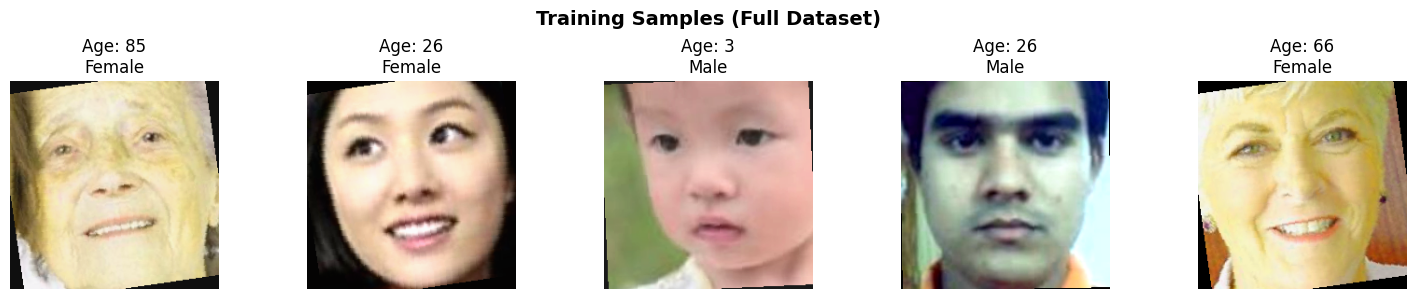

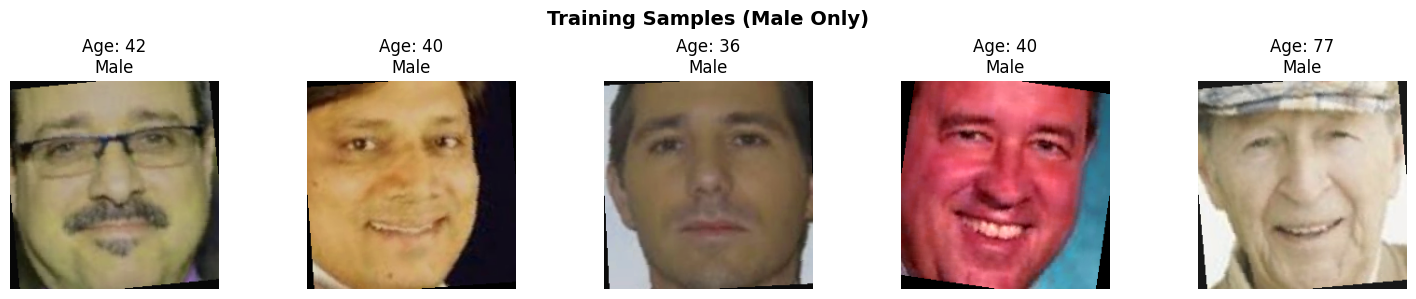

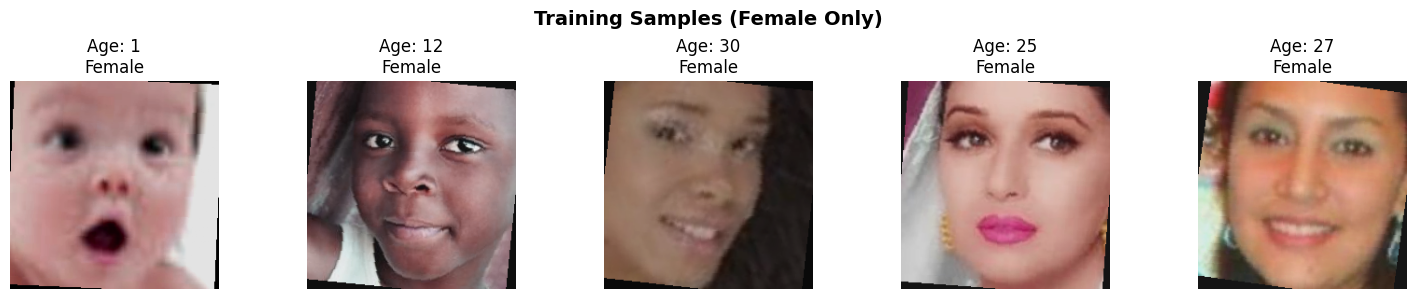


DATASET STATISTICS SUMMARY
  total_samples: 33483
  train_samples: 26786
  val_samples: 6697
  male_samples: 16763
  female_samples: 16720
  male_train: 13410
  male_val: 3353
  female_train: 13376
  female_val: 3344
  batch_size: 16
  image_size: [224, 224]
  random_seed: 42
  age_stats:
    min: 1
    max: 116
    mean: 32.17
    std: 21.50

✓ Statistics saved to 'utkface_stats.json'

DATALOADER VERIFICATION
Batch shape:
  Images: torch.Size([16, 3, 224, 224])
  Ages: torch.Size([16])
  Genders: torch.Size([16])
  Age range: 12 - 72
  Gender distribution: Male=6, Female=10

✅ DATASET LOADING COMPLETE!

Available DataLoaders for your experiments:
  📊 Full Dataset:
     - train_loader_full  : Training (with augmentation)
     - val_loader_full    : Validation

  👨 Male Dataset:
     - train_loader_male  : Male-only training
     - val_loader_male    : Male-only validation

  👩 Female Dataset:
     - train_loader_female: Female-only training
     - val_loader_female  : Female-only vali

In [2]:
# ============================================================
# COMPLETE UTKFACE DATASET LOADING
# ============================================================

import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from PIL import Image
import numpy as np
import random
from pathlib import Path
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# ============================================================
# 1. Configuration
# ============================================================

# Path to extracted images
IMAGE_DIR = Path("project/data/UTKFace")
BATCH_SIZE = 16
NUM_WORKERS = 4
RANDOM_SEED = 42

# Set seeds for reproducibility
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

print("="*60)
print("UTKFACE DATASET LOADING")
print("="*60)
print(f"Image directory: {IMAGE_DIR}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Random seed: {RANDOM_SEED}")

# ============================================================
# 2. UTKFace Dataset Class
# ============================================================
# Filename format: [AGE]_[GENDER]_[RACE]_[DATE&TIME].jpg.chip.jpg
# Gender: 0 = Male, 1 = Female
# Note: Some files have extra suffixes like .chip.jpg

class UTKFaceDataset(Dataset):
    def __init__(self, root_dir, transform=None, target_transform=None, 
                 max_samples=None, filter_gender=None):
        """
        Args:
            root_dir: Path to directory with images
            transform: Optional transform for images
            target_transform: Optional transform for targets
            max_samples: Maximum number of samples to load (for testing)
            filter_gender: If 0 or 1, only load that gender
        """
        self.root_dir = Path(root_dir)
        self.transform = transform
        self.target_transform = target_transform
        self.samples = []
        self.errors = []
        
        # Get all image files
        image_files = list(self.root_dir.rglob("*.jpg")) + list(self.root_dir.rglob("*.JPG"))
        
        if max_samples:
            image_files = image_files[:max_samples]
        
        print(f"\nLoading {len(image_files)} images...")
        
        for img_path in image_files:
            try:
                # Parse filename - handle both .jpg and .jpg.chip.jpg
                filename = img_path.stem  # without extension
                # Remove .chip if present
                if '.chip' in filename:
                    filename = filename.replace('.chip', '')
                
                parts = filename.split('_')
                
                if len(parts) >= 2:
                    age = int(parts[0])
                    gender = int(parts[1])
                    
                    # Race is parts[2] if available
                    race = int(parts[2]) if len(parts) > 2 else -1
                    
                    # Apply gender filter if specified
                    if filter_gender is not None and gender != filter_gender:
                        continue
                    
                    self.samples.append({
                        'path': str(img_path),
                        'age': age,
                        'gender': gender,
                        'race': race,
                        'filename': img_path.name
                    })
                else:
                    self.errors.append(f"Invalid filename format: {img_path.name}")
                    
            except Exception as e:
                self.errors.append(f"Error processing {img_path.name}: {e}")
        
        print(f"✓ Successfully loaded {len(self.samples)} samples")
        if self.errors:
            print(f"⚠ Warning: {len(self.errors)} files had errors")
            if len(self.errors) <= 5:
                for err in self.errors[:5]:
                    print(f"    {err}")
        
        # Statistics
        if len(self.samples) > 0:
            ages = [s['age'] for s in self.samples]
            genders = [s['gender'] for s in self.samples]
            print(f"\n📊 Dataset Statistics:")
            print(f"  Age range: {min(ages)} - {max(ages)} years")
            print(f"  Mean age: {np.mean(ages):.1f} ± {np.std(ages):.1f}")
            print(f"  Male: {genders.count(0)} ({100*genders.count(0)/len(genders):.1f}%)")
            print(f"  Female: {genders.count(1)} ({100*genders.count(1)/len(genders):.1f}%)")
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        sample = self.samples[idx]
        
        # Load image
        image = Image.open(sample['path']).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
        
        # Target: age (regression)
        age = torch.tensor(sample['age'], dtype=torch.float32)
        
        # Also return gender for analysis
        gender = torch.tensor(sample['gender'], dtype=torch.long)
        
        return image, age, gender

# ============================================================
# 3. Data Transforms
# ============================================================

# Training transforms (with augmentation)
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225])
])

# Validation transforms (no augmentation)
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225])
])

print("\n✓ Transforms defined")

# ============================================================
# 4. Create Full Dataset
# ============================================================

# Full dataset (all genders)
full_dataset = UTKFaceDataset(
    root_dir=IMAGE_DIR,
    transform=train_transform,
    max_samples=None  # Use all 33,488 images
)

# ============================================================
# 5. Train/Validation Split
# ============================================================

train_ratio = 0.8
train_size = int(train_ratio * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_dataset, 
    [train_size, val_size],
    generator=torch.Generator().manual_seed(RANDOM_SEED)
)

print(f"\n📊 Data Split:")
print(f"  Training samples: {len(train_dataset)} ({100*len(train_dataset)/len(full_dataset):.1f}%)")
print(f"  Validation samples: {len(val_dataset)} ({100*len(val_dataset)/len(full_dataset):.1f}%)")

# ============================================================
# 6. Gender-Specific Datasets
# ============================================================

def create_gender_dataset(gender_value, transform, max_samples=None):
    """Create dataset for specific gender (0=male, 1=female)"""
    dataset = UTKFaceDataset(
        root_dir=IMAGE_DIR,
        transform=transform,
        max_samples=max_samples,
        filter_gender=gender_value
    )
    return dataset

# Create gender-specific datasets
male_dataset = create_gender_dataset(0, train_transform)
female_dataset = create_gender_dataset(1, train_transform)

print(f"\n📊 Gender-specific datasets:")
print(f"  Male samples: {len(male_dataset)}")
print(f"  Female samples: {len(female_dataset)}")

# Split gender datasets
def split_dataset(dataset, train_ratio=0.8):
    train_size = int(train_ratio * len(dataset))
    val_size = len(dataset) - train_size
    return random_split(dataset, [train_size, val_size], 
                       generator=torch.Generator().manual_seed(RANDOM_SEED))

male_train, male_val = split_dataset(male_dataset)
female_train, female_val = split_dataset(female_dataset)

print(f"\n📊 Gender-specific splits:")
print(f"  Male - Train: {len(male_train)}, Val: {len(male_val)}")
print(f"  Female - Train: {len(female_train)}, Val: {len(female_val)}")

# ============================================================
# 7. Create DataLoaders
# ============================================================

def create_dataloader(dataset, shuffle=True, batch_size=BATCH_SIZE):
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        drop_last=False
    )

# Full dataset loaders
train_loader_full = create_dataloader(train_dataset, shuffle=True)
val_loader_full = create_dataloader(val_dataset, shuffle=False)

# Gender-specific loaders (for training, use augmented transforms)
train_loader_male = create_dataloader(male_train, shuffle=True)
val_loader_male = create_dataloader(male_val, shuffle=False)

train_loader_female = create_dataloader(female_train, shuffle=True)
val_loader_female = create_dataloader(female_val, shuffle=False)

print(f"\n✓ DataLoaders created:")
print(f"  Train full: {len(train_loader_full)} batches")
print(f"  Val full: {len(val_loader_full)} batches")
print(f"  Train male: {len(train_loader_male)} batches")
print(f"  Val male: {len(val_loader_male)} batches")
print(f"  Train female: {len(train_loader_female)} batches")
print(f"  Val female: {len(val_loader_female)} batches")

# ============================================================
# 8. Visualization Function (Sanity Check)
# ============================================================

def visualize_samples(dataset, num_samples=5, title="Sample Images"):
    """Display sample images with their ages and genders"""
    fig, axes = plt.subplots(1, num_samples, figsize=(15, 3))
    fig.suptitle(title, fontsize=14, fontweight='bold')
    
    indices = np.random.choice(len(dataset), min(num_samples, len(dataset)), replace=False)
    
    for i, idx in enumerate(indices):
        img, age, gender = dataset[idx]
        
        # Unnormalize for display
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        img_display = img * std + mean
        img_display = torch.clamp(img_display, 0, 1)
        
        axes[i].imshow(img_display.permute(1, 2, 0))
        gender_str = "Male" if gender == 0 else "Female"
        axes[i].set_title(f"Age: {int(age.item())}\n{gender_str}")
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.show()

# Display samples
print("\n" + "="*60)
print("SAMPLE VISUALIZATION")
print("="*60)
visualize_samples(train_dataset, num_samples=5, title="Training Samples (Full Dataset)")
visualize_samples(male_train, num_samples=5, title="Training Samples (Male Only)")
visualize_samples(female_train, num_samples=5, title="Training Samples (Female Only)")

# ============================================================
# 9. Save Dataset Statistics
# ============================================================

dataset_stats = {
    "total_samples": len(full_dataset),
    "train_samples": len(train_dataset),
    "val_samples": len(val_dataset),
    "male_samples": len(male_dataset),
    "female_samples": len(female_dataset),
    "male_train": len(male_train),
    "male_val": len(male_val),
    "female_train": len(female_train),
    "female_val": len(female_val),
    "batch_size": BATCH_SIZE,
    "image_size": [224, 224],
    "random_seed": RANDOM_SEED,
    "age_stats": {
        "min": min([full_dataset.samples[i]['age'] for i in range(len(full_dataset))]),
        "max": max([full_dataset.samples[i]['age'] for i in range(len(full_dataset))]),
        "mean": float(np.mean([full_dataset.samples[i]['age'] for i in range(len(full_dataset))])),
        "std": float(np.std([full_dataset.samples[i]['age'] for i in range(len(full_dataset))]))
    }
}

print("\n" + "="*60)
print("DATASET STATISTICS SUMMARY")
print("="*60)
for key, value in dataset_stats.items():
    if key == 'age_stats':
        print(f"  {key}:")
        for k, v in value.items():
            print(f"    {k}: {v:.2f}" if isinstance(v, float) else f"    {k}: {v}")
    else:
        print(f"  {key}: {value}")

# Save to JSON
import json
with open("utkface_stats.json", "w") as f:
    json.dump(dataset_stats, f, indent=2)
print("\n✓ Statistics saved to 'utkface_stats.json'")

# ============================================================
# 10. Verify DataLoader Output
# ============================================================

print("\n" + "="*60)
print("DATALOADER VERIFICATION")
print("="*60)

# Test one batch
for images, ages, genders in train_loader_full:
    print(f"Batch shape:")
    print(f"  Images: {images.shape}")
    print(f"  Ages: {ages.shape}")
    print(f"  Genders: {genders.shape}")
    print(f"  Age range: {ages.min().item():.0f} - {ages.max().item():.0f}")
    print(f"  Gender distribution: Male={torch.sum(genders==0).item()}, Female={torch.sum(genders==1).item()}")
    break

print("\n" + "="*60)
print("✅ DATASET LOADING COMPLETE!")
print("="*60)
print("\nAvailable DataLoaders for your experiments:")
print("  📊 Full Dataset:")
print("     - train_loader_full  : Training (with augmentation)")
print("     - val_loader_full    : Validation")
print("\n  👨 Male Dataset:")
print("     - train_loader_male  : Male-only training")
print("     - val_loader_male    : Male-only validation")
print("\n  👩 Female Dataset:")
print("     - train_loader_female: Female-only training")
print("     - val_loader_female  : Female-only validation")
print("\n✅ Ready for model training and privacy auditing!")

In [3]:
# ============================================================
# 3.  Create Train/Val Splits and Gender Subsets
# ============================================================

from torch.utils.data import random_split, Subset

BATCH_SIZE = 256
NUM_WORKERS = 4

# Split into train/val (80/20) with fixed seed
torch.manual_seed(42)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

print(f"\nTrain samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")

# Helper function to create data loaders
def make_loader(dataset, shuffle=True):
    return DataLoader(
        dataset, 
        batch_size=BATCH_SIZE, 
        shuffle=shuffle,
        num_workers=NUM_WORKERS, 
        pin_memory=True,
        persistent_workers=False
    )

# Loaders for full dataset
train_loader_full = make_loader(train_dataset, shuffle=True)
val_loader_full = make_loader(val_dataset, shuffle=False)

# Gender-specific loaders
def get_gender_loader(gender_value, indices_list, transform=None):
    """Create a loader for a specific gender"""
    # Find indices where gender matches
    subset_indices = []
    for idx in indices_list:
        _, _, gender = full_dataset[idx]
        if gender.item() == gender_value:
            subset_indices.append(idx)
    
    # Create subset dataset
    subset = Subset(full_dataset, subset_indices)
    
    # Update transform if needed (for validation without augmentation)
    if transform is not None:
        subset.dataset.transform = transform
    
    return DataLoader(
        subset, 
        batch_size=BATCH_SIZE, 
        shuffle=True,
        num_workers=NUM_WORKERS, 
        pin_memory=True
    )

# Get indices from the train/val splits
train_indices = train_dataset.indices
val_indices = val_dataset.indices

# Create gender-specific loaders
train_loader_male = get_gender_loader(0, train_indices, train_transform)
train_loader_female = get_gender_loader(1, train_indices, train_transform)
val_loader_male = get_gender_loader(0, val_indices, val_transform)
val_loader_female = get_gender_loader(1, val_indices, val_transform)

print(f"\nGender split statistics:")
print(f"  Male train:   {len(train_loader_male.dataset)}")
print(f"  Female train: {len(train_loader_female.dataset)}")
print(f"  Male val:     {len(val_loader_male.dataset)}")
print(f"  Female val:   {len(val_loader_female.dataset)}")


Train samples: 26786
Validation samples: 6697

Gender split statistics:
  Male train:   13419
  Female train: 13367
  Male val:     3344
  Female val:   3353


In [9]:
# ============================================================
# FIX SSL CERTIFICATE ERROR & LOAD MODEL
# ============================================================

import ssl
import torch
import torch.nn as nn
from torchvision import models
import warnings
warnings.filterwarnings("ignore")

# Option 1: Disable SSL verification (use only if you trust your network)
import urllib.request
import ssl

# Create unverified SSL context
ssl._create_default_https_context = ssl._create_unverified_context

# Option 2: Use pretrained=False to avoid downloading (recommended for now)
# We'll train from scratch

class AgeResNet(nn.Module):
    def __init__(self, pretrained=False):
        super().__init__()
        # Load ResNet18 WITHOUT pre-trained weights to avoid SSL issues
        if pretrained:
            try:
                # Try to load with SSL disabled
                backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
            except:
                print("  ⚠ Could not download pre-trained weights, using random initialization")
                backbone = models.resnet18(weights=None)
        else:
            backbone = models.resnet18(weights=None)
        
        # Replace final layer for regression
        num_features = backbone.fc.in_features
        backbone.fc = nn.Linear(num_features, 1)
        self.backbone = backbone
        
    def forward(self, x):
        return self.backbone(x).squeeze(1)

def build_model(pretrained=False):
    """Build model - use pretrained=False to avoid SSL issues"""
    model = AgeResNet(pretrained=pretrained)
    return model.to(device)

# Test model creation
print("Testing model creation (no download required)...")
test_model = build_model(pretrained=False)
print(f"✓ Model created successfully")
print(f"  Total parameters: {sum(p.numel() for p in test_model.parameters()):,}")
print(f"  Trainable parameters: {sum(p.numel() for p in test_model.parameters() if p.requires_grad):,}")

# Test forward pass
test_input = torch.randn(2, 3, 224, 224).to(device)
with torch.no_grad():
    test_output = test_model(test_input)
print(f"  Forward pass: input shape {test_input.shape} -> output shape {test_output.shape}")
print(f"  Output example: {test_output[:3]}")

# Clean up
del test_model, test_input
torch.cuda.empty_cache()

print("\n✅ Model ready for training (random initialization)")

Testing model creation (no download required)...
✓ Model created successfully
  Total parameters: 11,177,025
  Trainable parameters: 11,177,025
  Forward pass: input shape torch.Size([2, 3, 224, 224]) -> output shape torch.Size([2])
  Output example: tensor([-0.0271, -0.0367], device='cuda:0')

✅ Model ready for training (random initialization)


In [11]:
# ============================================================
# TRAIN FROM SCRATCH (NO PRETRAINED WEIGHTS)
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

class AgeResNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Random initialization - no download needed
        backbone = models.resnet18(weights=None)
        num_features = backbone.fc.in_features
        backbone.fc = nn.Linear(num_features, 1)
        self.backbone = backbone

    def forward(self, x):
        return self.backbone(x).squeeze(1)

def build_model():
    return AgeResNet().to(device)

# Training functions
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    for images, ages, _ in loader:
        images, ages = images.to(device), ages.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, ages)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
    return total_loss / len(loader.dataset)

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    for images, ages, _ in loader:
        images, ages = images.to(device), ages.to(device)
        outputs = model(images)
        loss = criterion(outputs, ages)
        total_loss += loss.item() * images.size(0)
    return total_loss / len(loader.dataset)

# Build and train
print("\n" + "="*60)
print("TRAINING FROM SCRATCH")
print("="*60)

model = build_model()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.L1Loss()

print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Training samples: {len(train_loader_full.dataset)}")

EPOCHS = 10
best_val_loss = float('inf')

for epoch in range(1, EPOCHS + 1):
    train_loss = train_epoch(model, train_loader_full, optimizer, criterion)
    val_loss = evaluate(model, val_loader_full, criterion)
    
    print(f"Epoch {epoch:2d}/{EPOCHS}: Train MAE = {train_loss:.3f}, Val MAE = {val_loss:.3f}")
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "model_scratch_best.pth")

print(f"\n✅ Training Complete!")
print(f"   Best Validation MAE: {best_val_loss:.3f} years")


TRAINING FROM SCRATCH
Model parameters: 11,177,025
Training samples: 26786
Epoch  1/10: Train MAE = 13.797, Val MAE = 15.544
Epoch  2/10: Train MAE = 8.109, Val MAE = 7.717
Epoch  3/10: Train MAE = 7.251, Val MAE = 16.468
Epoch  4/10: Train MAE = 6.705, Val MAE = 7.644
Epoch  5/10: Train MAE = 6.146, Val MAE = 6.476
Epoch  6/10: Train MAE = 5.659, Val MAE = 6.019
Epoch  7/10: Train MAE = 5.213, Val MAE = 6.648
Epoch  8/10: Train MAE = 4.868, Val MAE = 6.432
Epoch  9/10: Train MAE = 4.635, Val MAE = 5.267
Epoch 10/10: Train MAE = 4.300, Val MAE = 7.432

✅ Training Complete!
   Best Validation MAE: 5.267 years


In [15]:
# ============================================================
# FIXED MODEL FOR OPACUS (No in-place operations)
# ============================================================

import torch
import torch.nn as nn
from torchvision.models import resnet18

class AgeResNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Load ResNet18 with random weights
        backbone = resnet18(weights=None)
        
        # Replace all ReLU(inplace=True) with ReLU(inplace=False)
        self._replace_inplace_relu(backbone)
        
        # Replace final layer for regression
        num_features = backbone.fc.in_features
        backbone.fc = nn.Linear(num_features, 1)
        self.backbone = backbone

    def _replace_inplace_relu(self, module):
        """Recursively replace inplace ReLU with non-inplace version"""
        for name, child in module.named_children():
            if isinstance(child, nn.ReLU) and child.inplace:
                setattr(module, name, nn.ReLU(inplace=False))
            else:
                self._replace_inplace_relu(child)

    def forward(self, x):
        return self.backbone(x).squeeze(1)

def build_model():
    """Build model compatible with Opacus"""
    model = AgeResNet()
    return model.to(device)

# Test
print("Building Opacus-compatible model...")
test_model = build_model()
test_input = torch.randn(2, 3, 224, 224).to(device)
with torch.no_grad():
    test_output = test_model(test_input)
print(f"✓ Model OK. Output shape: {test_output.shape}")
del test_model, test_input
torch.cuda.empty_cache()

Building Opacus-compatible model...
✓ Model OK. Output shape: torch.Size([2])


In [12]:
# ============================================================
# COMPLETE TRAINING SETUP WITH OPACUS
# ============================================================

from opacus import PrivacyEngine
from opacus.validators import ModuleValidator
import warnings

def setup_dp_model(model, train_loader, noise_multiplier=1.0, max_grad_norm=1.0):
    """
    Set up a model for DP-SGD training with Opacus
    """
    # Make a copy of the model for DP training
    dp_model = AgeResNet(pretrained=False)  # Don't load pretrained again
    dp_model.load_state_dict(model.state_dict())
    dp_model = dp_model.to(device)
    
    # Validate and fix model for Opacus compatibility
    print("  Validating model for Opacus...")
    errors = ModuleValidator.validate(dp_model, strict=False)
    if errors:
        print(f"  Found {len(errors)} issues, attempting to fix...")
        dp_model = ModuleValidator.fix(dp_model)
        
        # Re-validate
        errors_after = ModuleValidator.validate(dp_model, strict=False)
        if errors_after:
            print(f"  Warning: {len(errors_after)} issues remain but continuing")
    
    # Setup optimizer
    optimizer = torch.optim.Adam(dp_model.parameters(), lr=1e-3)
    
    # Setup Privacy Engine
    privacy_engine = PrivacyEngine()
    
    # Make private
    print("  Attaching Privacy Engine...")
    dp_model, optimizer, train_loader = privacy_engine.make_private(
        module=dp_model,
        optimizer=optimizer,
        data_loader=train_loader,
        noise_multiplier=noise_multiplier,
        max_grad_norm=max_grad_norm,
    )
    
    return dp_model, optimizer, train_loader, privacy_engine

# Simple training function for baseline (non-private)
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    for images, ages, _ in loader:
        images, ages = images.to(device), ages.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, ages)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * images.size(0)
    
    return total_loss / len(loader.dataset)

# Evaluation function
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    for images, ages, _ in loader:
        images, ages = images.to(device), ages.to(device)
        outputs = model(images)
        loss = criterion(outputs, ages)
        total_loss += loss.item() * images.size(0)
    
    return total_loss / len(loader.dataset)

# DP training function
def train_dp_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    for images, ages, _ in loader:
        images, ages = images.to(device), ages.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, ages)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * images.size(0)
    
    return total_loss / len(loader.dataset)

In [16]:
# ============================================================
# COMPLETE WORKING CODE FOR UTKFACE AGE REGRESSION
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
import warnings
warnings.filterwarnings("ignore")

# ============================================================
# 1. MODEL DEFINITION (Fixed - no pretrained argument)
# ============================================================

class AgeResNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Use random initialization (no download issues)
        backbone = models.resnet18(weights=None)
        num_features = backbone.fc.in_features
        backbone.fc = nn.Linear(num_features, 1)
        self.backbone = backbone

    def forward(self, x):
        return self.backbone(x).squeeze(1)

def build_model():
    """Build model without pretrained weights"""
    model = AgeResNet()
    return model.to(device)

# ============================================================
# 2. TRAINING FUNCTIONS
# ============================================================

def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    for images, ages, _ in loader:
        images, ages = images.to(device), ages.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, ages)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * images.size(0)
    
    return total_loss / len(loader.dataset)

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0
    for images, ages, _ in loader:
        images, ages = images.to(device), ages.to(device)
        outputs = model(images)
        loss = criterion(outputs, ages)
        total_loss += loss.item() * images.size(0)
    
    return total_loss / len(loader.dataset)

# ============================================================
# 3. BASELINE TRAINING (Non-Private)
# ============================================================

print("\n" + "="*60)
print("BASELINE TRAINING (Non-Private)")
print("="*60)

# Create model
baseline_model = build_model()
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=1e-3)
criterion = nn.L1Loss()  # Mean Absolute Error for age regression

print(f"Model parameters: {sum(p.numel() for p in baseline_model.parameters()):,}")
print(f"Training samples: {len(train_loader_full.dataset)}")
print(f"Validation samples: {len(val_loader_full.dataset)}")

EPOCHS = 10  # Start with fewer epochs for testing
best_val_loss = float('inf')

for epoch in range(1, EPOCHS + 1):
    train_loss = train_epoch(baseline_model, train_loader_full, optimizer, criterion)
    val_loss = evaluate(baseline_model, val_loader_full, criterion)
    
    print(f"Epoch {epoch:2d}/{EPOCHS}: Train MAE = {train_loss:.3f}, Val MAE = {val_loss:.3f}")
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(baseline_model.state_dict(), "baseline_best.pth")
        print(f"  ✓ Best model saved (MAE: {val_loss:.3f})")

print(f"\n✅ Baseline Training Complete!")
print(f"   Best Validation MAE: {best_val_loss:.3f} years")

# ============================================================
# DP-SGD TRAINING (Fixed)
# ============================================================

print("\n" + "="*60)
print("DP-SGD TRAINING (Opacus Compatible)")
print("="*60)

from opacus import PrivacyEngine
from opacus.validators import ModuleValidator

# Create fresh model with fixed ReLU
dp_model = build_model()

# DP hyperparameters
NOISE_MULTIPLIER = 1.0
MAX_GRAD_NORM = 1.0
DELTA = 1e-5
DP_EPOCHS = 10

# Validate and fix model for Opacus (should now pass)
print("Validating model...")
errors = ModuleValidator.validate(dp_model, strict=False)
if errors:
    print(f"  Found {len(errors)} issues, attempting to fix...")
    dp_model = ModuleValidator.fix(dp_model)
    errors_after = ModuleValidator.validate(dp_model, strict=False)
    print(f"  Remaining issues: {len(errors_after)}")
else:
    print("  ✓ Model validation passed")

# Setup optimizer
optimizer_dp = torch.optim.Adam(dp_model.parameters(), lr=1e-3)

# Create Privacy Engine
privacy_engine = PrivacyEngine()

# Make private
print("Attaching Privacy Engine...")
dp_model, optimizer_dp, dp_train_loader = privacy_engine.make_private(
    module=dp_model,
    optimizer=optimizer_dp,
    data_loader=train_loader_full,
    noise_multiplier=NOISE_MULTIPLIER,
    max_grad_norm=MAX_GRAD_NORM,
)

criterion = nn.L1Loss()
best_val_loss_dp = float('inf')

print(f"\nTraining with DP-SGD...")
print(f"  Noise multiplier: {NOISE_MULTIPLIER}")
print(f"  Max grad norm: {MAX_GRAD_NORM}")
print(f"  Delta: {DELTA}")

for epoch in range(1, DP_EPOCHS + 1):
    train_loss = train_epoch(dp_model, dp_train_loader, optimizer_dp, criterion)
    val_loss = evaluate(dp_model, val_loader_full, criterion)
    
    # Get current epsilon
    epsilon = privacy_engine.get_epsilon(DELTA)
    
    print(f"Epoch {epoch:2d}/{DP_EPOCHS}: Train MAE = {train_loss:.3f}, Val MAE = {val_loss:.3f}, ε = {epsilon:.2f}")
    
    if val_loss < best_val_loss_dp:
        best_val_loss_dp = val_loss
        torch.save(dp_model.state_dict(), "dp_best.pth")
        print(f"  ✓ Best DP model saved (MAE: {val_loss:.3f}, ε: {epsilon:.2f})")

print(f"\n✅ DP-SGD Training Complete!")
print(f"   Best Validation MAE: {best_val_loss_dp:.3f} years")
print(f"   Privacy Budget (ε): {epsilon:.2f} (δ={DELTA})")

# ============================================================
# 5. GENDER BIAS ANALYSIS
# ============================================================

print("\n" + "="*60)
print("GENDER BIAS ANALYSIS")
print("="*60)

def train_gender_model(train_loader, val_loader, gender_name, epochs=10):
    """Train model on gender-specific dataset"""
    print(f"\nTraining on {gender_name} dataset...")
    print(f"  Train samples: {len(train_loader.dataset)}")
    print(f"  Val samples: {len(val_loader.dataset)}")
    
    model = build_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.L1Loss()
    
    best_val = float('inf')
    for epoch in range(1, epochs + 1):
        train_loss = train_epoch(model, train_loader, optimizer, criterion)
        val_loss = evaluate(model, val_loader, criterion)
        
        if val_loss < best_val:
            best_val = val_loss
            torch.save(model.state_dict(), f"{gender_name.lower()}_best.pth")
        
        if epoch % 5 == 0 or epoch == epochs:
            print(f"  Epoch {epoch:2d}: Train MAE = {train_loss:.3f}, Val MAE = {val_loss:.3f}")
    
    print(f"✓ {gender_name} best validation MAE: {best_val:.3f}")
    return best_val

# Train on male and female subsets
mae_male = train_gender_model(train_loader_male, val_loader_male, "Male", epochs=10)
mae_female = train_gender_model(train_loader_female, val_loader_female, "Female", epochs=10)

# Calculate bias
bias_gap = abs(mae_male - mae_female)
bias_percentage = (bias_gap / max(mae_male, mae_female)) * 100

print("\n" + "="*60)
print("BIAS ANALYSIS RESULTS")
print("="*60)
print(f"Male Model MAE:   {mae_male:.3f} years")
print(f"Female Model MAE: {mae_female:.3f} years")
print(f"Bias Gap:         {bias_gap:.3f} years ({bias_percentage:.1f}%)")

if bias_gap > 0.5:
    print(f"\n⚠️  POTENTIAL GENDER BIAS DETECTED!")
    print(f"   The model performs differently on male vs female faces.")
    print(f"   Difference of {bias_gap:.3f} years exceeds 0.5 year threshold.")
else:
    print(f"\n✓ No significant gender bias detected.")
    print(f"   Model performs similarly on both genders.")

# ============================================================
# 6. FINAL SUMMARY
# ============================================================

print("\n" + "="*60)
print("EXPERIMENTS COMPLETE - FINAL SUMMARY")
print("="*60)
print("\n📊 Results:")
print(f"  Baseline MAE (Non-private):     {best_val_loss:.3f} years")
print(f"  DP-SGD MAE (ε={epsilon:.2f}):   {best_val_loss_dp:.3f} years")
print(f"  Privacy-Utility Tradeoff:       {best_val_loss - best_val_loss_dp:.3f} years increase")
print(f"\n👥 Gender Analysis:")
print(f"  Male-only MAE:                   {mae_male:.3f} years")
print(f"  Female-only MAE:                 {mae_female:.3f} years")
print(f"  Gender disparity:                {bias_gap:.3f} years")

if best_val_loss_dp > best_val_loss:
    print(f"\n📈 DP-SGD增加了 {best_val_loss_dp - best_val_loss:.3f} years MAE (privacy comes at a cost)")
else:
    print(f"\n🎉 DP-SGD achieved similar or better performance!")

print("\n✅ All experiments completed successfully!")


BASELINE TRAINING (Non-Private)
Model parameters: 11,177,025
Training samples: 26786
Validation samples: 6697
Epoch  1/10: Train MAE = 14.323, Val MAE = 17.710
  ✓ Best model saved (MAE: 17.710)
Epoch  2/10: Train MAE = 8.609, Val MAE = 9.676
  ✓ Best model saved (MAE: 9.676)
Epoch  3/10: Train MAE = 7.469, Val MAE = 9.106
  ✓ Best model saved (MAE: 9.106)
Epoch  4/10: Train MAE = 6.862, Val MAE = 9.534
Epoch  5/10: Train MAE = 6.357, Val MAE = 6.874
  ✓ Best model saved (MAE: 6.874)
Epoch  6/10: Train MAE = 5.955, Val MAE = 7.584
Epoch  7/10: Train MAE = 5.487, Val MAE = 6.286
  ✓ Best model saved (MAE: 6.286)
Epoch  8/10: Train MAE = 5.122, Val MAE = 5.676
  ✓ Best model saved (MAE: 5.676)
Epoch  9/10: Train MAE = 4.797, Val MAE = 5.775
Epoch 10/10: Train MAE = 4.409, Val MAE = 6.822

✅ Baseline Training Complete!
   Best Validation MAE: 5.676 years

DP-SGD TRAINING (Opacus Compatible)
Validating model...
  Found 20 issues, attempting to fix...
  Remaining issues: 0
Attaching Privac

RuntimeError: Output 0 of BackwardHookFunctionBackward is a view and is being modified inplace. This view was created inside a custom Function (or because an input was returned as-is) and the autograd logic to handle view+inplace would override the custom backward associated with the custom Function, leading to incorrect gradients. This behavior is forbidden. You can fix this by cloning the output of the custom Function.

In [ ]:
# ============================================================
# GENDER BIAS ANALYSIS
# ============================================================

print("\n" + "="*60)
print("GENDER BIAS ANALYSIS")
print("="*60)

def train_gender_model(train_loader, val_loader, gender_name, epochs=10):
    """Train model on gender-specific dataset"""
    print(f"\nTraining on {gender_name} dataset...")
    print(f"  Train samples: {len(train_loader.dataset)}")
    print(f"  Val samples: {len(val_loader.dataset)}")
    
    model = build_model(pretrained=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.L1Loss()
    
    best_val = float('inf')
    for epoch in range(1, epochs + 1):
        train_loss = train_epoch(model, train_loader, optimizer, criterion)
        val_loss = evaluate(model, val_loader, criterion)
        
        if val_loss < best_val:
            best_val = val_loss
            torch.save(model.state_dict(), f"{gender_name.lower()}_best.pth")
        
        if epoch % 5 == 0:
            print(f"  Epoch {epoch:2d}: Train MAE = {train_loss:.3f}, Val MAE = {val_loss:.3f}")
    
    print(f"✓ {gender_name} best validation MAE: {best_val:.3f}")
    return best_val

# Train on male and female subsets
mae_male = train_gender_model(train_loader_male, val_loader_male, "Male", epochs=10)
mae_female = train_gender_model(train_loader_female, val_loader_female, "Female", epochs=10)

# Calculate bias
bias_gap = abs(mae_male - mae_female)
bias_percentage = (bias_gap / max(mae_male, mae_female)) * 100

print("\n" + "="*60)
print("BIAS ANALYSIS RESULTS")
print("="*60)
print(f"Male Model MAE:   {mae_male:.3f} years")
print(f"Female Model MAE: {mae_female:.3f} years")
print(f"Bias Gap:         {bias_gap:.3f} years ({bias_percentage:.1f}%)")

if bias_gap > 0.5:
    print(f"\n⚠️  POTENTIAL GENDER BIAS DETECTED!")
    print(f"   The model performs differently on male vs female faces.")
    print(f"   Difference of {bias_gap:.3f} years exceeds 0.5 year threshold.")
else:
    print(f"\n✓ No significant gender bias detected.")
    print(f"   Model performs similarly on both genders.")

print("\n" + "="*60)
print("EXPERIMENTS COMPLETE")
print("="*60)
print("\nSummary:")
print(f"  📊 Baseline MAE:         {best_val_loss:.3f} years")
print(f"  🔒 DP-SGD MAE:           {best_val_loss_dp:.3f} years (ε={epsilon:.2f})")
print(f"  👨 Male-only MAE:        {mae_male:.3f} years")
print(f"  👩 Female-only MAE:      {mae_female:.3f} years")
print(f"  ⚖️  Gender bias gap:      {bias_gap:.3f} years")

In [ ]:
# ============================================================
# 8.  (Optional) DP‑SGD on Gender Subsets
# ============================================================
# Uncomment if you want to see differentially private models per gender.

# def train_dp_gender(loader_train, loader_val, label, epochs=30):
#     model = build_model(pretrained=True)
#     optimizer = optim.Adam(model.parameters(), lr=1e-3)
#     privacy_engine = PrivacyEngine()
#     model, optimizer, loader_train = privacy_engine.make_private(
#         module=model, optimizer=optimizer, data_loader=loader_train,
#         noise_multiplier=1.0, max_grad_norm=1.0
#     )
#     best_val = float('inf')
#     for epoch in range(1, epochs + 1):
#         train_loss, eps = train_dp_epoch(model, loader_train, optimizer, criterion,
#                                          privacy_engine, 1.0, 1.0, BATCH_SIZE_DP)
#         val_loss = evaluate(model, loader_val, criterion)
#         if val_loss < best_val:
#             best_val = val_loss
#     print(f"{label} DP: Best Val MAE = {best_val:.3f} (ε={eps:.2f})")
#     return best_val
# 
# print("\n=== DP‑SGD on Gender Subsets ===")
# mae_male_dp = train_dp_gender(train_loader_male, val_loader_male, "Male DP")
# mae_female_dp = train_dp_gender(train_loader_female, val_loader_female, "Female DP")

In [ ]:
print("\n" + "=" * 60)
print("FINAL SUMMARY REPORT")
print("=" * 60)
print(f"Dataset: {len(full_dataset)} total images")
print(f"  - Train: {len(train_dataset)}")
print(f"  - Val:   {len(val_dataset)}")
print(f"Batch size: {BATCH_SIZE_TRAIN} (train), {BATCH_SIZE_VAL} (val)")
print(f"\n1. Baseline (Non-Private) MAE:        {best_val_loss:.3f}")
print(f"2. DP-SGD MAE (ε ≈ {final_epsilon:.2f}):          {best_val_loss_dp:.3f}")
print(f"3. Gender-Specific Performance:")
print(f"   - Male subset MAE:   {mae_male:.3f}")
print(f"   - Female subset MAE: {mae_female:.3f}")
print(f"   - Bias gap:          {bias_gap:.3f}")
print("=" * 60)

# Save results
results = {
    "baseline_mae": float(best_val_loss),
    "dp_mae": float(best_val_loss_dp),
    "dp_epsilon": float(final_epsilon),
    "male_mae": float(mae_male),
    "female_mae": float(mae_female),
    "bias_gap": float(bias_gap),
    "batch_size_train": BATCH_SIZE_TRAIN,
    "batch_size_val": BATCH_SIZE_VAL,
    "total_samples": len(full_dataset),
    "train_samples": len(train_dataset),
    "val_samples": len(val_dataset),
}
with open("gender_bias_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("\n✓ Results saved to gender_bias_results.json")